# 06 · Reject inference (SecondLook extra)

**The bias.** A lender only learns whether a loan was repaid if it *granted* the loan. A model trained on those
outcomes has never seen the kind of applicant the lender used to decline, and thin-file applicants are declined more
often, so the blind spot lands exactly where SecondLook wants to help.

**Reject inference** adds declined applicants back into training with *inferred* outcomes. We compare two standard methods:

| Method | How declined applicants are added |
|---|---|
| **Fuzzy augmentation** | each one twice: as a default with weight *p* and as a repayment with weight *1 − p*, where *p* is the approved-only model's estimate |
| **Parcelling** | random outcomes at their score band's default rate × 1.5, assuming declined applicants are riskier than approved ones with the same score |

**How we can tell whether it works.** Real declined applicants never get a loan, so there is nothing to check the
inferred outcomes against. We therefore run the standard **simulation**:

1. A conventional lender (our bureau-only model from notebook 03) declines the riskiest **30%** of applicants. Their outcomes are hidden.
2. **Approved-only:** SecondLook trained on the 70% it approved, the biased model a real lender would have.
3. **Reject inference:** the same, plus the hidden 30% with inferred outcomes.
4. **Oracle:** SecondLook trained on everyone (notebook 03), the best achievable.

All models are scored on the **full test split**, where every outcome is known. The question is how much of the
gap between approved-only and the oracle reject inference recovers, especially for applicants the old policy declined
and for thin-file applicants.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # import secondlook from src/ (no pip install needed)

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

from secondlook.config import FIGURES_DIR, MODELS_DIR, TARGET_COL
from secondlook.features import load_features
from secondlook.modeling import LGBM_PARAMS, feature_sets, load_bundle, prepare, train_lightgbm
from secondlook.reject_inference import approval_at_bad_rate, fuzzy_augment, out_of_fold_scores, parcel, simulate_policy

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"Approved-only": "#8C8C8C", "Parcelling": "#55A868", "Fuzzy augmentation": "#DD8452", "Oracle (all outcomes)": "#4C72B0"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Simulate the conventional lender's policy

In [2]:
df = prepare(load_features())
cols = feature_sets(df)["secondlook"]
conv = load_bundle("conventional_lgbm")
oracle = load_bundle("secondlook_lgbm")

split = {s: df[df["split"] == s] for s in ["train", "valid", "test"]}
policy = {s: conv["model"].predict_proba(d[conv["columns"]])[:, 1] for s, d in split.items()}

# The conventional model was TRAINED on the train split, so its train-split scores are in-sample:
# it partly remembers who defaulted, and its "declined" group would be unrealistically full of real
# defaulters. Out-of-fold scores (each fifth scored by a model fitted on the other four) fix that.
# Valid and test keep the full model, which never saw them.
policy["train"] = out_of_fold_scores(split["train"][conv["columns"]], split["train"][TARGET_COL],
                                     n_estimators=conv["model"].best_iteration_, params=LGBM_PARAMS)

REJECT_SHARE = 0.30
approved_train, POLICY_CUTOFF = simulate_policy(policy["train"], REJECT_SHARE)
approved = {s: policy[s] <= POLICY_CUTOFF for s in split}

summary = pd.DataFrame({
    s: {"applicants": len(d), "declined by policy": 1 - approved[s].mean(),
        "default rate, approved": d.loc[approved[s], TARGET_COL].mean(),
        "default rate, declined": d.loc[~approved[s], TARGET_COL].mean(),
        "thin-file share, approved": d.loc[approved[s], "THIN_FILE"].mean(),
        "thin-file share, declined": d.loc[~approved[s], "THIN_FILE"].mean()}
    for s, d in split.items()}).T
summary.style.format({"applicants": "{:,.0f}", **{c: "{:.1%}" for c in summary.columns if c != "applicants"}})

,applicants,declined by policy,"default rate, approved","default rate, declined","thin-file share, approved","thin-file share, declined"
train,"184,507",30.0%,3.9%,17.8%,11.8%,20.2%
valid,"46,126",30.3%,3.8%,17.8%,12.0%,19.7%
test,"46,126",30.2%,3.9%,17.8%,11.7%,20.3%


The declined group defaults far more often, and thin-file applicants are over-represented in it: exactly the
population an approved-only model never learns from.

## 2. Train approved-only and reject-inference models

In [3]:
tr, va = split["train"], split["valid"]
X_acc, y_acc = tr.loc[approved["train"], cols], tr.loc[approved["train"], TARGET_COL].to_numpy()
X_rej = tr.loc[~approved["train"], cols]
# Early stopping uses only APPROVED validation applicants: a real lender has no outcomes for the rest.
X_va, y_va = va.loc[approved["valid"], cols], va.loc[approved["valid"], TARGET_COL].to_numpy()

models = {}
models["Approved-only"] = train_lightgbm(X_acc, y_acc, X_va, y_va)
p_acc = models["Approved-only"].predict_proba(X_acc)[:, 1]
p_rej = models["Approved-only"].predict_proba(X_rej)[:, 1]
print(f"Approved-only model: mean predicted default among the declined {p_rej.mean():.1%} "
      f"(their true rate, hidden from training: {tr.loc[~approved['train'], TARGET_COL].mean():.1%})")

X, y, w = fuzzy_augment(X_acc, y_acc, X_rej, p_rej)
models["Fuzzy augmentation"] = train_lightgbm(X, y, X_va, y_va, sample_weight=w)

X, y, w = parcel(X_acc, y_acc, p_acc, X_rej, p_rej, inflation=1.5)
models["Parcelling"] = train_lightgbm(X, y, X_va, y_va, sample_weight=w)
print("Inferred default rate among the declined (parcelling):", f"{y[len(y_acc):].mean():.1%}")

models["Oracle (all outcomes)"] = oracle["model"]
for name, m in models.items():
    print(f"  {name:24s} {m.best_iteration_} trees")

Approved-only model: mean predicted default among the declined 13.6% (their true rate, hidden from training: 17.8%)


Inferred default rate among the declined (parcelling): 35.0%
  Approved-only            495 trees
  Fuzzy augmentation       625 trees
  Parcelling               894 trees
  Oracle (all outcomes)    830 trees


## 3. Results on the full test split

In [4]:
te = split["test"]
y_te = te[TARGET_COL].to_numpy()
thin_te = te["THIN_FILE"].to_numpy().astype(bool)
declined_te = ~approved["test"]
scores = {name: m.predict_proba(te[cols])[:, 1] for name, m in models.items()}

rows = {}
for name, p in scores.items():
    rows[name] = {
        "AUC, all": roc_auc_score(y_te, p),
        "AUC, declined by old policy": roc_auc_score(y_te[declined_te], p[declined_te]),
        "AUC, thin-file": roc_auc_score(y_te[thin_te], p[thin_te]),
        **{f"{k} @ {t:.0%}": v for t in [0.04, 0.05]
           for k, v in approval_at_bad_rate(y_te, p, thin_te, t).items()},
    }
res = pd.DataFrame(rows).T
res.columns = [c.replace("thin_approval_rate", "thin-file approved").replace("approval_rate", "approved") for c in res.columns]

base, top = res.loc["Approved-only"], res.loc["Oracle (all outcomes)"]
gap = ((res - base) / (top - base)).loc[["Fuzzy augmentation", "Parcelling"]]
display(res.style.format({c: "{:.4f}" if "AUC" in c else "{:.1%}" for c in res.columns}))
print("Share of the approved-only -> oracle gap recovered:")
display(gap.style.format("{:.0%}"))

,"AUC, all","AUC, declined by old policy","AUC, thin-file",approved @ 4%,thin-file approved @ 4%,approved @ 5%,thin-file approved @ 5%
Approved-only,0.7637,0.6476,0.7398,71.5%,60.8%,81.6%,73.2%
Fuzzy augmentation,0.7663,0.6537,0.7431,72.0%,61.8%,82.4%,74.7%
Parcelling,0.7658,0.6442,0.7385,71.7%,60.6%,82.2%,73.4%
Oracle (all outcomes),0.7756,0.6769,0.7549,74.2%,64.3%,84.1%,78.1%


Share of the approved-only -> oracle gap recovered:


,"AUC, all","AUC, declined by old policy","AUC, thin-file",approved @ 4%,thin-file approved @ 4%,approved @ 5%,thin-file approved @ 5%
Fuzzy augmentation,22%,21%,22%,18%,29%,32%,31%
Parcelling,18%,-12%,-8%,7%,-4%,25%,4%


**Are these differences bigger than noise?** The AUC differences are small, so we bootstrap the test split
(resample applicants with replacement 300 times, score every model on the same resample) and report a 95% interval
for each method's AUC minus the approved-only model's AUC. An interval that excludes 0 is a real improvement.

In [5]:
rng = np.random.default_rng(0)
segments = {"all": np.ones(len(y_te), bool), "declined by old policy": declined_te, "thin-file": thin_te}
boot = []
for _ in range(300):
    idx = rng.integers(0, len(y_te), len(y_te))
    for seg, mask in segments.items():
        i = idx[mask[idx]]
        base_auc = roc_auc_score(y_te[i], scores["Approved-only"][i])
        for name in ["Fuzzy augmentation", "Parcelling"]:
            boot.append({"segment": seg, "method": name, "diff": roc_auc_score(y_te[i], scores[name][i]) - base_auc})
boot = pd.DataFrame(boot)
ci = boot.groupby(["method", "segment"])["diff"].agg(
    mean="mean", low=lambda d: d.quantile(0.025), high=lambda d: d.quantile(0.975)).reset_index()
ci["significant"] = (ci["low"] > 0) | (ci["high"] < 0)
ci.style.format({"mean": "{:+.4f}", "low": "{:+.4f}", "high": "{:+.4f}"}).hide(axis="index")

method,segment,mean,low,high,significant
Fuzzy augmentation,all,+0.0026,+0.0007,+0.0046,True
Fuzzy augmentation,declined by old policy,+0.0062,+0.0014,+0.0107,True
Fuzzy augmentation,thin-file,+0.0034,-0.0014,+0.0091,False
Parcelling,all,+0.0022,-0.0005,+0.0049,False
Parcelling,declined by old policy,-0.0032,-0.0094,+0.0034,False
Parcelling,thin-file,-0.0012,-0.0095,+0.0066,False


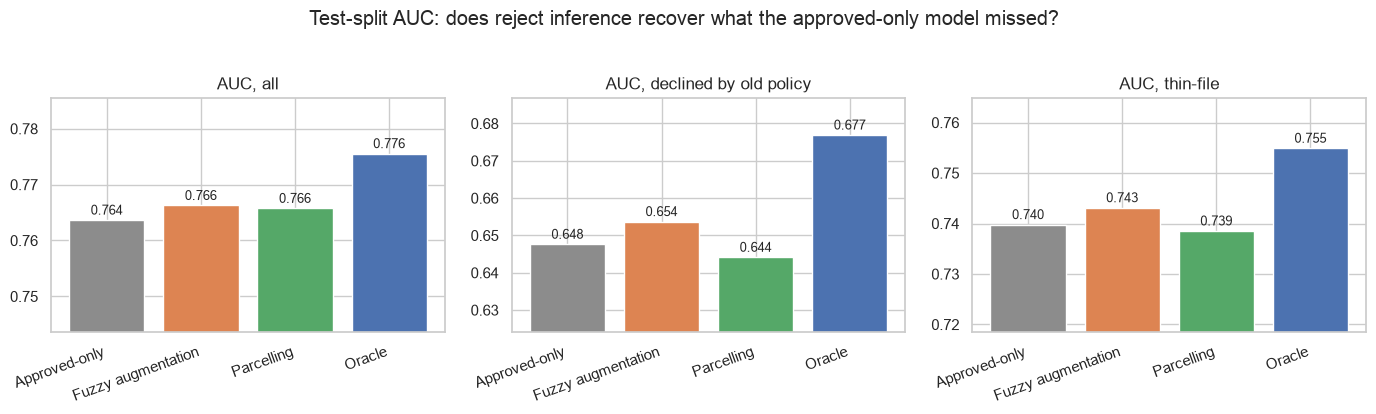

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["AUC, all", "AUC, declined by old policy", "AUC, thin-file"]):
    vals = res[col]
    bars = ax.bar(range(len(vals)), vals, color=[COLORS[n] for n in vals.index])
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in vals], padding=2, fontsize=9)
    ax.set_xticks(range(len(vals)), [n.replace(" (all outcomes)", "") for n in vals.index], rotation=20, ha="right")
    lo = vals.min()
    ax.set(title=col, ylim=(lo - 0.02, vals.max() + 0.01))
fig.suptitle("Test-split AUC: does reject inference recover what the approved-only model missed?", y=1.03)
savefig("23_reject_inference_auc")

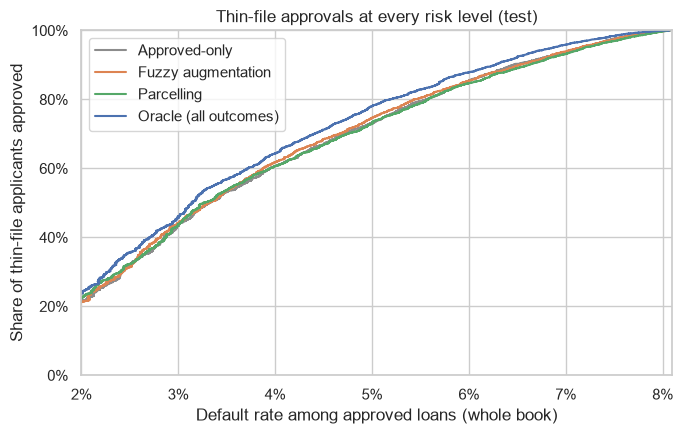

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, p in scores.items():
    order = np.argsort(p, kind="stable")
    bad = np.cumsum(y_te[order]) / np.arange(1, len(y_te) + 1)
    thin_share = np.cumsum(thin_te[order]) / thin_te.sum()
    keep = np.arange(len(y_te)) >= 2000
    ax.plot(bad[keep], thin_share[keep], color=COLORS[name], label=name)
ax.set(xlim=(0.02, 0.081), ylim=(0, 1), xlabel="Default rate among approved loans (whole book)",
       ylabel="Share of thin-file applicants approved", title="Thin-file approvals at every risk level (test)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend()
savefig("24_reject_inference_tradeoff")

## 4. Does it hold when the old policy is stricter or looser?
We repeat the approved-only vs fuzzy-augmentation comparison with the old policy declining 20% and 40% of applicants.

In [8]:
sens = []
for share in [0.20, 0.30, 0.40]:
    acc_tr, cut = simulate_policy(policy["train"], share)
    acc_va = policy["valid"] <= cut
    Xa, ya = tr.loc[acc_tr, cols], tr.loc[acc_tr, TARGET_COL].to_numpy()
    Xr = tr.loc[~acc_tr, cols]
    Xv, yv = va.loc[acc_va, cols], va.loc[acc_va, TARGET_COL].to_numpy()
    if share == REJECT_SHARE:
        m_acc, m_fz = models["Approved-only"], models["Fuzzy augmentation"]
    else:
        m_acc = train_lightgbm(Xa, ya, Xv, yv)
        X, y, w = fuzzy_augment(Xa, ya, Xr, m_acc.predict_proba(Xr)[:, 1])
        m_fz = train_lightgbm(X, y, Xv, yv, sample_weight=w)
    dec = policy["test"] > cut
    for name, m in [("Approved-only", m_acc), ("Fuzzy augmentation", m_fz)]:
        p = m.predict_proba(te[cols])[:, 1]
        sens.append({"declined by old policy": share, "model": name,
                     "AUC, all": roc_auc_score(y_te, p),
                     "AUC, declined": roc_auc_score(y_te[dec], p[dec]),
                     "AUC, thin-file": roc_auc_score(y_te[thin_te], p[thin_te])})
sens = pd.DataFrame(sens).pivot(index="declined by old policy", columns="model")
sens.style.format("{:.4f}")

## Takeaways

Simulation: a conventional lender declines the riskiest 30% of applicants; all models are scored on the full test split, where every outcome is known.

1. **Training only on approved loans costs accuracy, most of all where SecondLook wants to help.** Compared with a model that saw every outcome, the approved-only model loses 0.012 AUC overall and 0.015 on thin-file applicants, and approves 3.5 points fewer thin-file applicants at a 4% default rate (60.8% vs 64.3%).
2. **Fuzzy augmentation recovers part of that, and it is a real effect.** It recovers about 22% of the overall and thin-file AUC gaps. A 300-sample bootstrap confirms the gains overall (+0.0026 AUC, 95% interval +0.0007 to +0.0046) and among applicants the old policy declined (+0.0062, +0.0014 to +0.0107). The thin-file gain (+0.0034) is suggestive but its interval includes zero.
3. **It depends on how strict the old policy was.** Fuzzy augmentation beats approved-only when the old policy declined 20% or 30% of applicants; at 40% the two are about level (slightly worse on the declined and thin-file groups), so a lender should validate it on its own policy before relying on it.
4. **Parcelling is not recommended.** Its overall gain is not significant, and it does worse than doing nothing on the declined and thin-file groups, because its fixed 1.5x inflation guesses the declined group's risk instead of estimating it.
5. **A methodology lesson.** The first version of this simulation scored training applicants with the conventional model that had been trained on them; it "remembered" who defaulted, making the declined group unrealistically risky (21% vs a true 18%) and every result misleading. Out-of-fold scoring fixed it, and the approved group's default rate now matches across train, valid and test (3.8-3.9%).
6. **Next step for a real lender:** apply fuzzy augmentation to its genuinely declined applicants. Here the simulation is the evidence; Home Credit's own refused applications have no outcomes to validate against.